# Clasificación de clientes insatisfechos en Olist

Taller final de Ingeniería de la Información. Se busca identificar a los clientes insatisfechos (reseña de 1 a 3 estrellas) del dataset público de Olist, siguiendo las cuatro etapas de la analítica: descriptiva, diagnóstica, predictiva y prescriptiva.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
RUTA = "dataset/"

## 1. Datos

Se unen las tablas para obtener una fila por pedido con reseña.

In [2]:
fechas = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
          "order_delivered_customer_date", "order_estimated_delivery_date"]
leer = lambda nombre, **kw: pd.read_csv(f"{RUTA}olist_{nombre}_dataset.csv", **kw)

pedidos = leer("orders", parse_dates=fechas)
resenas = leer("order_reviews", parse_dates=["review_answer_timestamp"])
items = leer("order_items", parse_dates=["shipping_limit_date"])
productos = leer("products")
pagos = leer("order_payments")
clientes = leer("customers", dtype={"customer_zip_code_prefix": str})
vendedores = leer("sellers", dtype={"seller_zip_code_prefix": str})
geo = leer("geolocation", dtype={"geolocation_zip_code_prefix": str})

In [3]:
dias = lambda delta: delta.dt.total_seconds() / 86400

# Algunos pedidos tienen más de una reseña: se deja la última
resenas = resenas.sort_values(["review_answer_timestamp", "review_id"], kind="mergesort").drop_duplicates("order_id", keep="last")
df = pedidos.merge(resenas[["order_id", "review_score", "review_comment_message"]], on="order_id")
df["insatisfecho"] = (df["review_score"] <= 3).astype(int)

df["entregado"] = (df["order_status"] == "delivered").astype(int)
df["dias_entrega_real"] = dias(df["order_delivered_customer_date"] - df["order_purchase_timestamp"])
df["dias_entrega_estimada"] = dias(df["order_estimated_delivery_date"] - df["order_purchase_timestamp"])
df["dias_retraso"] = dias(df["order_delivered_customer_date"] - df["order_estimated_delivery_date"])

items = items.merge(productos, on="product_id", how="left").sort_values(["order_id", "order_item_id"], kind="mergesort")
por_pedido = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"), n_vendedores=("seller_id", "nunique"),
    precio_total=("price", "sum"), flete_total=("freight_value", "sum"),
    peso_total_g=("product_weight_g", "sum"), fotos_prom=("product_photos_qty", "mean"),
    limite_envio=("shipping_limit_date", "max"), categoria=("product_category_name", "first"),
    seller_id=("seller_id", "first"))
df = df.merge(por_pedido, on="order_id", how="left")
df["dias_despacho_vs_limite"] = dias(df["order_delivered_carrier_date"] - df["limite_envio"])
df = df.merge(pagos.groupby("order_id")["payment_installments"].max().rename("cuotas"), on="order_id", how="left")

# Distancia vendedor-cliente (haversine) con el promedio de coordenadas de cada código postal
coords = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()
df = (df.merge(clientes, on="customer_id", how="left")
        .merge(vendedores, on="seller_id", how="left")
        .merge(coords.add_prefix("cli_"), left_on="customer_zip_code_prefix", right_index=True, how="left")
        .merge(coords.add_prefix("ven_"), left_on="seller_zip_code_prefix", right_index=True, how="left"))
lat1, lon1, lat2, lon2 = (np.radians(df[c]) for c in ["cli_geolocation_lat", "cli_geolocation_lng", "ven_geolocation_lat", "ven_geolocation_lng"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["distancia_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df["estado_entrega"] = np.select([(df["entregado"] == 0) | df["dias_retraso"].isna(), df["dias_retraso"] > 0],
                                 ["No entregado", "Tarde"], "A tiempo")
print(f"Pedidos con reseña: {len(df):,}  |  insatisfechos: {df['insatisfecho'].mean():.1%}")

Pedidos con reseña: 98,673  |  insatisfechos: 22.9%


## 2. Analítica descriptiva

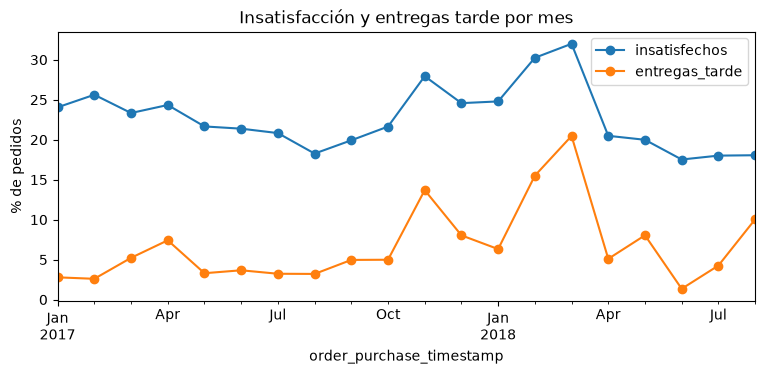

insatisfecho
0    0.347
1    0.635
Name: deja comentario, dtype: float64


,size,mean
categoria,,
moveis_escritorio,1255,0.368924
cama_mesa_banho,9211,0.264792
telefonia,4151,0.253674
moveis_decoracao,6305,0.250595
consoles_games,1048,0.242366


In [4]:
mensual = (df.groupby(df["order_purchase_timestamp"].dt.to_period("M"))
             .agg(pedidos=("order_id", "size"), insatisfechos=("insatisfecho", "mean"),
                  entregas_tarde=("estado_entrega", lambda s: (s == "Tarde").mean()))
             .query("pedidos >= 500"))
mensual[["insatisfechos", "entregas_tarde"]].mul(100).plot(figsize=(9, 3.5), marker="o", ylabel="% de pedidos",
                                                           title="Insatisfacción y entregas tarde por mes")
plt.show()

print(df.groupby("insatisfecho")["review_comment_message"].apply(lambda s: s.notna().mean()).rename("deja comentario").round(3))
df.groupby("categoria")["insatisfecho"].agg(["size", "mean"]).query("size >= 1000").sort_values("mean", ascending=False).head(5)

El 22,9 % de los clientes queda insatisfecho, con picos en noviembre de 2017 y febrero-marzo de 2018. Los insatisfechos dejan comentario casi el doble de veces que los satisfechos.

## 3. Analítica diagnóstica

                 size   mean
estado_entrega              
A tiempo        88163  0.172
No entregado     2849  0.856
Tarde            7661  0.654 

Correlación mensual insatisfacción - entregas tarde: 0.73


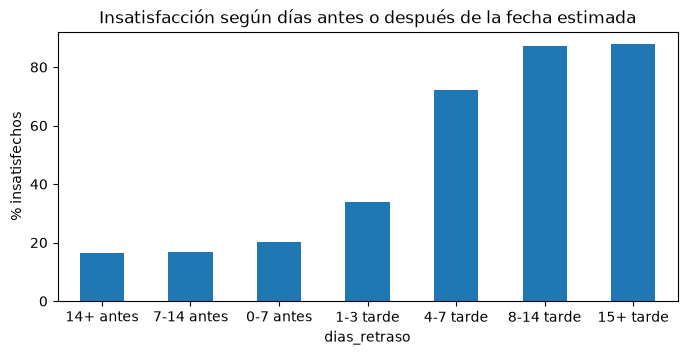

In [5]:
print(df.groupby("estado_entrega")["insatisfecho"].agg(["size", "mean"]).round(3), "\n")
print("Correlación mensual insatisfacción - entregas tarde:", round(mensual["insatisfechos"].corr(mensual["entregas_tarde"]), 2))

entregados = df[df["estado_entrega"] != "No entregado"]
tramos = pd.cut(entregados["dias_retraso"], [-np.inf, -14, -7, 0, 3, 7, 14, np.inf],
                labels=["14+ antes", "7-14 antes", "0-7 antes", "1-3 tarde", "4-7 tarde", "8-14 tarde", "15+ tarde"])
entregados.groupby(tramos, observed=True)["insatisfecho"].mean().mul(100).plot.bar(
    rot=0, figsize=(8, 3.5), ylabel="% insatisfechos", title="Insatisfacción según días antes o después de la fecha estimada")
plt.show()

In [6]:
insat = df[df["insatisfecho"] == 1]
print(insat["estado_entrega"].value_counts(normalize=True).round(3), "\n")

# Palabras clave en los comentarios de los insatisfechos
quejas = {
    "Retraso o no recibido": r"atras|demor|prazo|n[ãa]o receb|n[ãa]o cheg|ainda n[ãa]o",
    "Pedido incompleto": r"falt|incomplet|s[óo] receb|apenas um|veio s[óo]|somente um",
    "Producto diferente": r"diferente|errad|trocad|outro produto|n[ãa]o era",
    "Producto dañado": r"quebrad|defeit|danificad|estragad|n[ãa]o funciona|amassad",
    "Calidad o falsificación": r"qualidade|falsificad|fr[áa]gil|porcaria|vagabund",
}
texto = insat["review_comment_message"].dropna().str.lower()
a_tiempo = insat.loc[texto.index, "estado_entrega"] == "A tiempo"
pd.DataFrame({q: [texto[a_tiempo].str.contains(p).mean(), texto[~a_tiempo].str.contains(p).mean()]
              for q, p in quejas.items()}, index=["A tiempo", "Tarde o no entregado"]).T.mul(100).round(1)

estado_entrega
A tiempo        0.671
Tarde           0.222
No entregado    0.108
Name: proportion, dtype: float64 



,A tiempo,Tarde o no entregado
Retraso o no recibido,20.5,55.4
Pedido incompleto,12.7,4.1
Producto diferente,9.5,2.1
Producto dañado,8.1,1.3
Calidad o falsificación,7.4,1.2


Llegar tarde sube la insatisfacción de 17 % a 65 %, pero el 67 % de los insatisfechos recibió a tiempo y sus quejas son sobre el producto (incompleto, diferente, dañado). Hipótesis: un modelo con variables del pedido detectará la insatisfacción por retraso, pero no la causada por el producto.

## 4. Analítica predictiva

Mismo procedimiento para los dos intentos: partición 80/20 estratificada, un hiperparámetro por modelo elegido con una partición de validación (20 % del entrenamiento) y evaluación final en prueba. Criterio: F1 > 0,7 en ambas clases.

In [7]:
MODELOS = {
    "Decision Tree": (DecisionTreeClassifier(random_state=SEMILLA), "max_depth", [3, 5, 10, 20, 40, None]),
    "Random Forest": (RandomForestClassifier(random_state=SEMILLA, n_jobs=-1), "n_estimators", [10, 50, 100, 200]),
    "KNN": (KNeighborsClassifier(), "n_neighbors", [1, 3, 5, 11, 21, 51]),
    "Regresión logística": (LogisticRegression(max_iter=2000), "C", [0.01, 0.1, 1, 10]),
    "MLP": (MLPClassifier(random_state=SEMILLA, early_stopping=True), "hidden_layer_sizes", [(10,), (50,), (100,), (100, 50)]),
}

def submuestrear(X, y):
    """Deja tantos ejemplos de la clase 0 como de la clase 1."""
    rng = np.random.RandomState(SEMILLA)
    i1 = np.where(y == 1)[0]
    i0 = rng.choice(np.where(y == 0)[0], len(i1), replace=False)
    idx = np.concatenate([i0, i1])
    rng.shuffle(idx)
    return X[idx], y[idx]

def entrenar(X_ent, y_ent, X_pru, y_pru, balancear=False):
    X_a, X_val, y_a, y_val = train_test_split(X_ent, y_ent, test_size=0.2, random_state=SEMILLA, stratify=y_ent)
    if balancear:
        X_a, y_a = submuestrear(X_a, y_a)
        X_ent, y_ent = submuestrear(X_ent, y_ent)
    validacion, resultados, modelos = [], [], {}
    for nombre, (base, param, valores) in MODELOS.items():
        f1_val = [f1_score(y_val, clone(base).set_params(**{param: v}).fit(X_a, y_a).predict(X_val), average=None)
                  for v in valores]
        validacion += [(nombre, str(v), *f.round(3)) for v, f in zip(valores, f1_val)]
        mejor = valores[int(np.argmax([f.min() for f in f1_val]))]
        modelos[nombre] = clone(base).set_params(**{param: mejor}).fit(X_ent, y_ent)
        f1 = f1_score(y_pru, modelos[nombre].predict(X_pru), average=None)
        resultados.append((nombre, f"{param}={mejor}", *f1.round(3)))
    cols = ["modelo", "valor", "f1_satisfecho", "f1_insatisfecho"]
    return pd.DataFrame(resultados, columns=cols).set_index("modelo"), pd.DataFrame(validacion, columns=cols), modelos

def recall_por_entrega(modelo, X, y, grupo):
    """Proporción de insatisfechos detectados según el estado de la entrega."""
    pred = modelo.predict(X)
    return pd.Series(pred[y == 1]).groupby(grupo[y == 1]).mean().round(3)

### 4.1 Intento 1: variables del pedido

Se imputan faltantes con la mediana, se estandariza y se submuestrea la clase mayoritaria en el entrenamiento (solo hay 23 % de insatisfechos).

In [8]:
VARIABLES = ["entregado", "dias_entrega_real", "dias_entrega_estimada", "dias_retraso", "dias_despacho_vs_limite",
             "n_items", "n_vendedores", "precio_total", "flete_total", "peso_total_g", "distancia_km", "cuotas", "fotos_prom"]

X_ent, X_pru, y_ent, y_pru, g_ent, g_pru = train_test_split(
    df[VARIABLES], df["insatisfecho"].values, df["estado_entrega"].values,
    test_size=0.2, random_state=SEMILLA, stratify=df["insatisfecho"].values)
medianas = X_ent.median()
escalador = StandardScaler().fit(X_ent.fillna(medianas))
X_ent, X_pru = escalador.transform(X_ent.fillna(medianas)), escalador.transform(X_pru.fillna(medianas))

res1, val1, modelos1 = entrenar(X_ent, y_ent, X_pru, y_pru, balancear=True)
res1

,valor,f1_satisfecho,f1_insatisfecho
modelo,,,
Decision Tree,max_depth=5,0.870,0.510
Random Forest,n_estimators=200,0.832,0.496
KNN,n_neighbors=51,0.845,0.504
Regresión logística,C=0.1,0.829,0.495
MLP,"hidden_layer_sizes=(10,)",0.830,0.499


In [9]:
val1.pivot_table(index=["modelo", "valor"], values=["f1_satisfecho", "f1_insatisfecho"], sort=False)

f1_satisfecho  f1_insatisfecho
modelo              valor                                    
Decision Tree       3                  0.871            0.496
                    5                  0.869            0.502
                    10                 0.849            0.489
                    20                 0.775            0.440
                    40                 0.700            0.411
                    None               0.691            0.407
Random Forest       10                 0.813            0.463
                    50                 0.826            0.486
                    100                0.832            0.492
                    200                0.833            0.493
KNN                 1                  0.704            0.417
                    3                  0.734            0.430
                    5                  0.756            0.442
                    11                 0.792            0.457
                    21                 0.817            0.469
                    51                 0.848            0.500
Regresión logística 0.01               0.826            0.486
                    0.1                0.826            0.486
                    1                  0.826            0.486
                    10                 0.826            0.486
MLP                 (10,)              0.842            0.501
                    (50,)              0.842            0.498
                    (100,)             0.842            0.498
                    (100, 50)          0.848            0.499

In [10]:
recall1 = recall_por_entrega(modelos1["Decision Tree"], X_pru, y_pru, g_pru)
recall1

A tiempo        0.221
No entregado    0.993
Tarde           0.933
dtype: float64

Ningún modelo supera 0,7 en la clase insatisfecho (máximo 0,51). El árbol sin límite de profundidad baja en validación: memoriza. El análisis por entrega confirma la hipótesis: el modelo detecta casi todos los insatisfechos con retraso o sin entrega, pero solo el 22 % de los que recibieron a tiempo. La información que falta está en el comentario, que deja el 63,5 % de los insatisfechos.

### 4.2 Intento 2: texto de la reseña

Bolsa de palabras binaria: cada palabra que aparece en al menos 5 comentarios del entrenamiento es una columna (1 si aparece, 0 si no).

In [11]:
com = df.dropna(subset=["review_comment_message"]).reset_index(drop=True)
T_ent, T_pru, yt_ent, yt_pru, gt_ent, gt_pru = train_test_split(
    com["review_comment_message"], com["insatisfecho"].values, com["estado_entrega"].values,
    test_size=0.2, random_state=SEMILLA, stratify=com["insatisfecho"].values)

vectorizador = CountVectorizer(binary=True, min_df=5)
Xt_ent, Xt_pru = vectorizador.fit_transform(T_ent), vectorizador.transform(T_pru)
print(f"{len(com):,} comentarios, {Xt_ent.shape[1]:,} palabras")

res2, val2, modelos2 = entrenar(Xt_ent, yt_ent, Xt_pru, yt_pru)
res2

40,775 comentarios, 3,219 palabras


,valor,f1_satisfecho,f1_insatisfecho
modelo,,,
Decision Tree,max_depth=40,0.890,0.784
Random Forest,n_estimators=200,0.918,0.851
KNN,n_neighbors=3,0.890,0.774
Regresión logística,C=1,0.921,0.850
MLP,"hidden_layer_sizes=(100, 50)",0.918,0.855


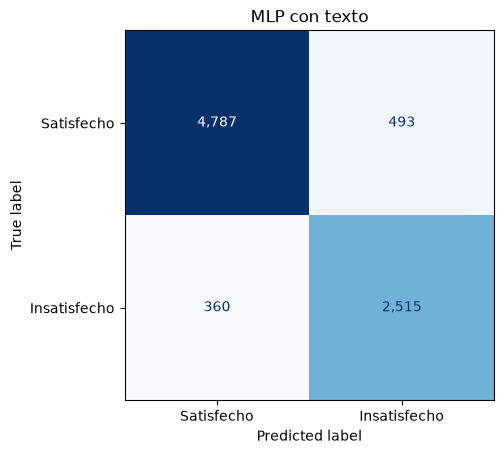

,pedido,texto
A tiempo,0.221,0.838
No entregado,0.993,0.951
Tarde,0.933,0.937


In [12]:
mejor = modelos2["MLP"]
ConfusionMatrixDisplay(confusion_matrix(yt_pru, mejor.predict(Xt_pru)), display_labels=["Satisfecho", "Insatisfecho"]).plot(
    cmap="Blues", colorbar=False, values_format=",")
plt.title("MLP con texto")
plt.show()

pd.DataFrame({"pedido": recall1, "texto": recall_por_entrega(mejor, Xt_pru, yt_pru, gt_pru)})

In [13]:
logistica = LogisticRegression(max_iter=2000).fit(Xt_ent, yt_ent)
pesos = pd.Series(logistica.coef_[0], index=vectorizador.get_feature_names_out()).sort_values()
pd.DataFrame({"insatisfecho": pesos.index[::-1][:10], "peso": pesos.values[::-1][:10].round(2),
              "satisfecho": pesos.index[:10], "peso ": pesos.values[:10].round(2)})

,insatisfecho,peso,satisfecho,peso
0,péssima,2.90,excelente,-2.74
1,atrasada,2.58,ótimo,-2.52
2,porcaria,2.43,otimo,-2.43
3,péssimo,2.39,amei,-2.38
4,pessima,2.25,adorei,-2.35
5,entrar,2.22,show,-2.33
6,insatisfeita,2.13,parabéns,-2.22
7,baixa,2.11,maravilhoso,-2.16
8,ruim,2.11,surpreendeu,-2.13
9,inferior,2.07,testei,-2.06


In [14]:
nuevos = ["Chegou antes do prazo, produto excelente. Recomendo!", "Ainda não recebi meu pedido e ninguém responde.",
          "O produto veio quebrado.", "Produto bom, mas a entrega demorou muito.", "Tudo certo, recebi conforme o anúncio."]
pd.DataFrame({"comentario": nuevos, "prob_insatisfecho": mejor.predict_proba(vectorizador.transform(nuevos))[:, 1].round(3)})

,comentario,prob_insatisfecho
0,"Chegou antes do prazo, produto excelente. Reco...",0.002
1,Ainda não recebi meu pedido e ninguém responde.,0.989
2,O produto veio quebrado.,0.960
3,"Produto bom, mas a entrega demorou muito.",0.634
4,"Tudo certo, recebi conforme o anúncio.",0.038


Con el texto los cinco modelos superan 0,7 en ambas clases; el mejor es la MLP `(100, 50)` con F1 de 0,918 y 0,855. Detecta también a los insatisfechos que recibieron a tiempo (84 % frente a 22 % del intento 1). La mejora viene del cambio de variables, no del algoritmo. Limitación: la bolsa de palabras no considera el orden ("não é ruim") y solo el 41 % de los clientes comenta.

## 5. Analítica prescriptiva

- Clasificar los comentarios al recibirlos y atender primero los marcados como insatisfechos.
- Vigilar los pedidos en riesgo de retraso y avisar al cliente antes de la fecha estimada.
- Reforzar la logística en noviembre y febrero-marzo.
- Informar cuando un pedido viene de varios vendedores y llega en envíos separados (61 % de insatisfechos).
- Hacer seguimiento a vendedores con despachos tardíos y a productos con quejas recurrentes.